# Rubin transients with FLARE

### From the SASSAFRAS simulations to your own classifier

The **Vera C. Rubin Observatory** will discover millions of transients each year in six filters
(*u g r i z y*). Nobody has a spectrum for most of them, so the first question is always the same:
**what is this thing, judging only from how its brightness changes with time?**

In this lesson you take a public set of simulated Rubin light curves, feed them through
**FLARE** (*Feature-based Light-curve Aggregated Ranking Ensemble*, the photometric classifier of
AppleCiDEr, built for the Zwicky Transient Facility), and find out what survives the jump from one
telescope to another.

**The plan**

| Part | What you do | What you learn |
|---|---|---|
| 1 | Open the SASSAFRAS catalogue | what a simulation header tells you |
| 2 | Look at raw Rubin light curves | detections, forced photometry, calibrated flux |
| 3 | Convert them into FLARE event arrays | the one data format behind every FLARE model |
| 4 | Count what survives | Rubin cadence versus fast transients |
| 5 | Extract 160 physical features | turning curves into numbers |
| 6 | Run the pretrained ZTF model on Rubin data | domain shift, measured |
| 7 | Train a Rubin classifier | gradient boosting, early stopping, class balance |
| 8 | Build prediction *sets* | conformal prediction: honest uncertainty |
| 9 | Find the kilonovae without ever training on them | anomaly energy |

> **Data.** SASSAFRAS (Amanda Wasserman, 2026, [Zenodo 10.5281/zenodo.20262635](https://zenodo.org/records/20262635))
> contains ~2.1 million simulated spectroscopic follow-up observations of LSST-like transients, with
> their light curves and simulation headers, for fourteen transient models at redshift 0.023 to 1.
> Three parquet files are published:
>
> | file | size | content | used here |
> |---|---|---|---|
> | `sassafrass_headers.parquet` | 163 MB | one row per object: true type, redshift, host galaxy, peak epoch | **yes** |
> | `sassafrass_phot.parquet` | 831 MB | one row per object: Rubin *ugrizy* light curve as list columns | **yes** |
> | `sassafrass_spectra.parquet` | 7.6 GB | simulated follow-up spectra (4MOST, Gemini, SOAR) | no (photometry only) |
>
> **Requirements.** The `flare` package and its dependencies (`light-curve`, `lightgbm`, `pyarrow`,
> `scikit-learn`, `matplotlib`). Part 0 needs the two parquet files; everything after it runs from the
> small cache that Part 0 writes, so the lesson itself works on a laptop.

In [1]:
# --- Setup ---------------------------------------------------------------
import os, sys, time, json, contextlib, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq

LESSON_DIR = Path.cwd()
DATA_DIR = Path(os.environ.get("SASSAFRAS_DATA", LESSON_DIR / "data"))      # the two Zenodo parquet files
PREP_DIR = LESSON_DIR / "prepared"                                            # cache written by Part 0
PREP_DIR.mkdir(exist_ok=True)
FLARE_REPO = Path(os.environ.get("FLARE_REPO", LESSON_DIR.parent / "flare")) # clone of applecider-ml/flare
if FLARE_REPO.exists():
    sys.path.insert(0, str(FLARE_REPO))

import flare
from flare import data as D
from flare.features import extract_from_array
assert hasattr(flare, "load_classifier"), "wrong `flare` on the path: run this notebook from its own folder"
print("flare", flare.__version__, "from", flare.__file__)

HEADERS = DATA_DIR / "sassafrass_headers.parquet"
PHOT = DATA_DIR / "sassafrass_phot.parquet"
print("Zenodo files present:", HEADERS.exists() and PHOT.exists())

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

flare 2.0.0 from ../flare/__init__.py
Zenodo files present: True


## 1. The catalogue: fourteen kinds of explosion

The headers file is the "truth table" of the simulation: one row per object with the model that
generated it, its redshift, its host galaxy, and when it peaked. We group the fourteen simulation
models into **eight teaching classes**, so that each class has a distinct physical story:

| class | models in SASSAFRAS | the physics | typical duration |
|---|---|---|---|
| **SN Ia** | SNIa-SALT3, SNIa-91bg, SNIax | thermonuclear explosion of a white dwarf | weeks |
| **SN Ibc** | SNIb, SNIc, SNIc-BL | core collapse of a star that lost its envelope | weeks |
| **SN II** | SNIIb, SNIIn | core collapse with hydrogen still around | weeks to months |
| **SLSN** | SLSN-I | superluminous supernova, a magnetar-powered giant | months |
| **TDE** | TDE | a star shredded by a supermassive black hole | months, stays blue |
| **KN** | KN_B19, KN_K17 | kilonova: neutron stars merging (the GW170817 kind) | **days** |
| **CART** | CART | calcium-rich transient, faint and fast | weeks |
| **ILOT** | ILOT | intermediate-luminosity optical transient | weeks |

There are no active galactic nuclei and no variable stars here: SASSAFRAS is a catalogue of
*explosions that someone would want a spectrum of*. Keep that in mind in Part 6.

In [2]:
TEACHING_CLASS = {
    "SNIa-SALT3": "SN Ia", "SNIa-91bg": "SN Ia", "SNIax": "SN Ia",
    "SNIb+HostXT_V19": "SN Ibc", "SNIc+HostXT_V19": "SN Ibc", "SNIcBL+HostXT_V19": "SN Ibc",
    "SNIIb+HostXT_V19": "SN II", "SNIIn+HostXT_V19": "SN II",
    "SLSN-I+host": "SLSN", "TDE": "TDE",
    "KN_B19": "KN", "KN_K17": "KN",
    "CART": "CART", "ILOT": "ILOT",
}
CLASSES = ["SN Ia", "SN Ibc", "SN II", "SLSN", "TDE", "KN", "CART", "ILOT"]
CLASS_ID = {c: i for i, c in enumerate(CLASSES)}
CLASS_COLOR = dict(zip(CLASSES, plt.cm.magma(np.linspace(0.08, 0.88, len(CLASSES)))))

HEADER_COLS = ["SNID", "obj_type", "telescope", "REDSHIFT_FINAL", "HOSTGAL_PHOTOZ", "HOSTGAL_SNSEP",
               "HOSTGAL_MAG_g", "HOSTGAL_MAG_r", "HOSTGAL_MAG_i", "PEAKMJD", "MJD_DETECT_FIRST",
               "NOBS", "MWEBV", "SIM_PEAKMAG_r", "SIM_MODEL_NAME"]
headers = pq.read_table(HEADERS, columns=HEADER_COLS).to_pandas(ignore_metadata=True)
headers["SNID"] = headers["SNID"].str.strip()
headers["cls"] = headers["obj_type"].map(TEACHING_CLASS)
print(f"{len(headers):,} simulated objects, {headers.SNID.nunique():,} unique IDs")
headers.head()

367,426 simulated objects, 367,426 unique IDs


,SNID,obj_type,telescope,REDSHIFT_FINAL,HOSTGAL_PHOTOZ,HOSTGAL_SNSEP,HOSTGAL_MAG_g,HOSTGAL_MAG_r,HOSTGAL_MAG_i,PEAKMJD,MJD_DETECT_FIRST,NOBS,MWEBV,SIM_PEAKMAG_r,SIM_MODEL_NAME,cls
0,10645860,SNIc+HostXT_V19,4most,0.145980,0.168675,0.708166,21.428473,20.674631,20.318018,61093.382812,61080.316406,221,0.043258,22.117508,NON1ASED,SN Ibc
1,10631785,SNIc+HostXT_V19,4most,0.067975,0.180014,0.377413,21.468412,20.323114,19.796331,61483.621094,61559.406250,109,0.100611,19.215773,NON1ASED,SN Ibc
2,10679366,SNIc+HostXT_V19,4most,0.225678,0.181725,1.507198,20.445894,19.637489,19.266329,61714.234375,61709.285156,50,0.013743,21.259243,NON1ASED,SN Ibc
3,10053839,SNIc+HostXT_V19,4most,0.372440,0.316090,0.279155,23.068048,21.619974,21.020468,61039.187500,61112.355469,78,0.038749,22.386574,NON1ASED,SN Ibc
4,11259898,SNIc+HostXT_V19,4most,0.308160,0.234284,1.524938,21.229126,19.794970,19.088428,61581.441406,61582.429688,161,0.031343,23.061739,NON1ASED,SN Ibc


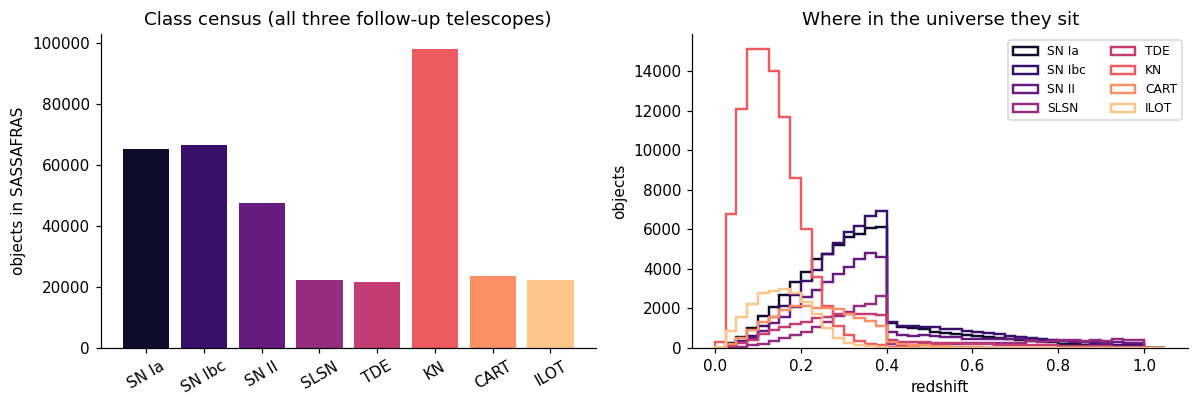

cls       SN Ia  SN Ibc  SN II   SLSN    TDE     KN  CART   ILOT
median z  0.313   0.331  0.328  0.357  0.302  0.124  0.24  0.156


In [3]:
census = headers.groupby(["cls", "obj_type"]).size().unstack(0).fillna(0).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
counts = headers.cls.value_counts().reindex(CLASSES)
axes[0].bar(CLASSES, counts.values, color=[CLASS_COLOR[c] for c in CLASSES])
axes[0].set_ylabel("objects in SASSAFRAS"); axes[0].set_title("Class census (all three follow-up telescopes)")
axes[0].tick_params(axis="x", rotation=30)
for c in CLASSES:
    z = headers.loc[headers.cls == c, "REDSHIFT_FINAL"]
    axes[1].hist(z, bins=np.linspace(0, 1.05, 43), histtype="step", lw=1.6, color=CLASS_COLOR[c], label=c)
axes[1].set_xlabel("redshift"); axes[1].set_ylabel("objects"); axes[1].set_title("Where in the universe they sit")
axes[1].legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()
print(headers.groupby("cls").REDSHIFT_FINAL.median().reindex(CLASSES).round(3).rename("median z").to_frame().T)

**Read the two panels together.** Kilonovae and calcium-rich transients are intrinsically faint, so the
simulation only places them nearby (low redshift). Superluminous supernovae and TDEs are bright
enough to be seen halfway across the observable universe. The `telescope` column (4MOST, Gemini, SOAR)
concerns the *spectroscopic* follow-up that SASSAFRAS simulated; the Rubin light curves are the same
kind of data for all three, so we use every object.

## 2. A raw Rubin light curve

The photometry file stores, per object, lists of epochs with the SNANA conventions:

- `mjd`: the night of the observation (Modified Julian Date);
- `band`: one of `LSST-u`, `LSST-g`, `LSST-r`, `LSST-i`, `LSST-z`, `LSST-Y`;
- `fluxcal`, `fluxcalerr`: calibrated flux on a zero point of 27.5 mag, so $m = 27.5 - 2.5\log_{10}(\mathrm{FLUXCAL})$;
- `photflag`: a bit mask. Bit 4096 means *the pipeline detected the source in this image*; bit 2048 marks
  the epoch that triggered the alert. An epoch with `photflag == 0` is **forced photometry**: the
  telescope looked, and measured a flux consistent with noise.

That last point is the first thing to teach about survey data: most rows of a light curve are
*non-detections*, and they are information (the object was not there yet, or had faded), but they
are not points you can take a logarithm of.

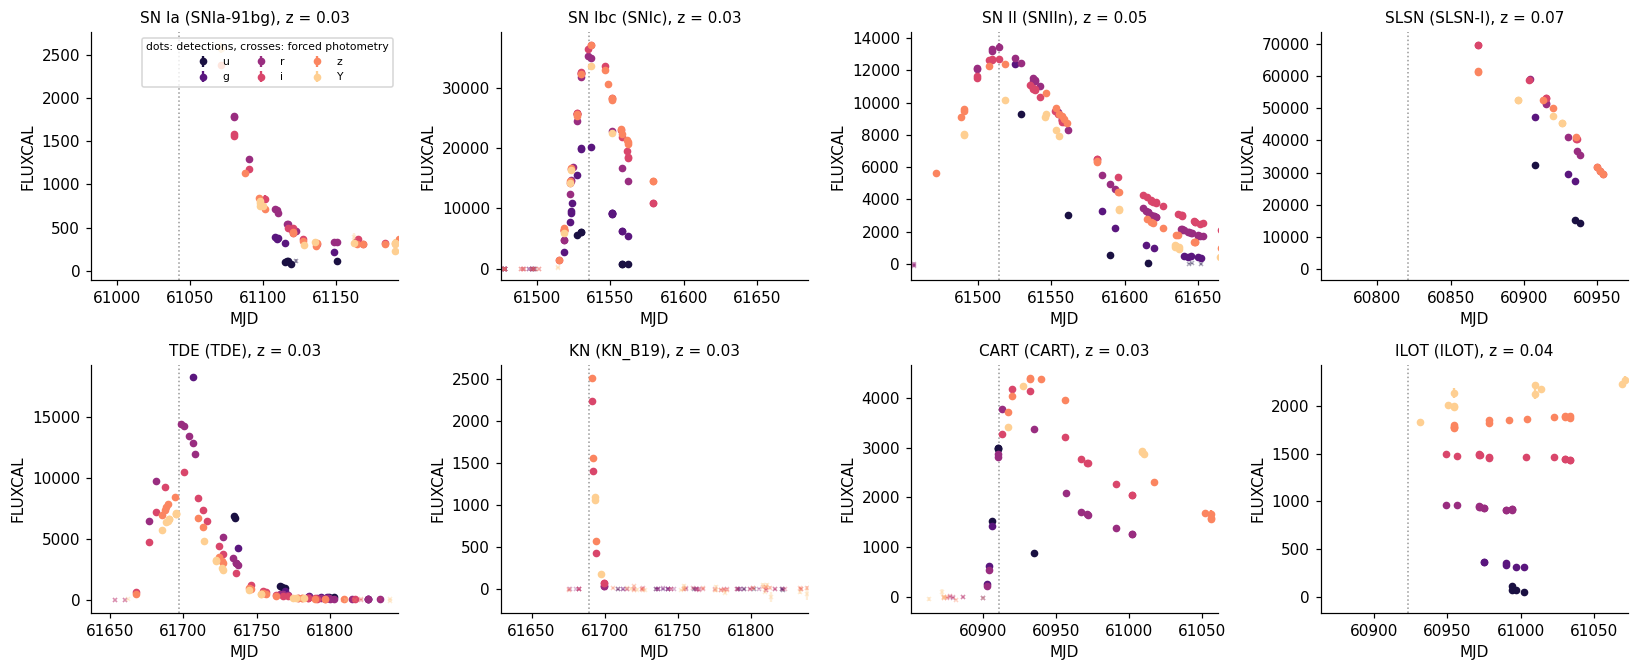

In [4]:
def read_phot(snids=None, obj_type=None, columns=("SNID", "mjd", "band", "photflag", "fluxcal", "fluxcalerr")):
    # A filtered read of the big parquet file: pyarrow scans the file once and keeps only matching rows.
    filters = []
    if snids is not None:
        filters.append(("SNID", "in", [f"{s:<16s}" for s in snids]))   # SNIDs are stored space-padded
    if obj_type is not None:
        filters.append(("obj_type", "==", obj_type))
    df = pq.read_table(PHOT, columns=list(columns), filters=filters or None).to_pandas(ignore_metadata=True)
    df["SNID"] = df["SNID"].str.strip()
    return df

BAND_ORDER = ["u", "g", "r", "i", "z", "Y"]
BAND_COLOR = dict(zip(BAND_ORDER, plt.cm.magma(np.linspace(0.12, 0.9, 6))))

def plot_raw(row, header, ax):
    mjd, flux, err = np.asarray(row.mjd, float), np.asarray(row.fluxcal, float), np.asarray(row.fluxcalerr, float)
    band = np.array([b.strip()[-1] for b in row.band])
    det = (np.asarray(row.photflag).astype(int) & 4096) > 0
    for b in BAND_ORDER:
        m = band == b
        ax.errorbar(mjd[m & det], flux[m & det], err[m & det], fmt="o", ms=4, color=BAND_COLOR[b], label=b)
        ax.errorbar(mjd[m & ~det], flux[m & ~det], err[m & ~det], fmt="x", ms=3, alpha=0.35, color=BAND_COLOR[b])
    ax.axvline(header.PEAKMJD, color="0.6", ls=":", lw=1)
    ax.set_xlim(header.PEAKMJD - 60, header.PEAKMJD + 150)
    ax.set_title(f"{header.cls} ({header.obj_type.split('+')[0]}), z = {header.REDSHIFT_FINAL:.2f}", fontsize=10)
    ax.set_xlabel("MJD"); ax.set_ylabel("FLUXCAL")

# one well-observed example per class: among the 30 brightest objects of each class, the one with most detections
cand = headers.sort_values("SIM_PEAKMAG_r").groupby("cls").head(30)
cand = read_phot(snids=cand.SNID.tolist()).merge(cand, on="SNID")
cand["n_det"] = [int(((np.asarray(f).astype(int) & 4096) > 0).sum()) for f in cand.photflag]
example = cand.sort_values("n_det", ascending=False).groupby("cls").head(1).set_index("cls", drop=False).loc[CLASSES]
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2))
for ax, (cls, h) in zip(axes.ravel(), example.iterrows()):
    plot_raw(h, h, ax)
axes[0, 0].legend(fontsize=7, ncol=3, title="dots: detections, crosses: forced photometry", title_fontsize=7)
plt.tight_layout(); plt.show()

These are the brightest object of each class, so they are the best case. Even so, every panel shows the
Rubin **Wide-Fast-Deep cadence** at work: a given filter returns to a field every few nights at best, the
six filters take turns, and whole weeks are lost to the Moon and the weather. A supernova that stays
bright for a month collects a reasonable curve. A kilonova that fades in three days is a handful of
points. The dotted line is the true peak epoch from the simulation header.

## 3. From SNANA rows to a FLARE event array

FLARE does not read parquet, FITS, or alert packets. Every model in the package, from the ZTF
classifier to the anomaly layer, consumes **one array per object** with fifteen columns per
observation. The columns are listed in `flare.data.COL`:

| column | meaning |
|---|---|
| `dt` | days since the first detection of the object |
| `dt_prev` | days since the previous observation |
| `band_id` | 0 = g, 1 = r, 2 = i |
| `logflux`, `logflux_err` | $\log_{10}$ of the flux in µJy, and its error in dex |
| `band_ztfg`, `band_ztfr`, `band_ztfi` | one-hot copy of the band |
| `g_r`, `g_r_err`, `r_i`, `r_i_err`, `has_g_r`, `has_r_i` | colours from pairs of observations within 1.5 days |
| `label` | class index at training time, −1 otherwise |

Writing the converter is the heart of this lesson, because every decision in it is a physics decision:

1. **Which bands?** FLARE knows *g, r, i*. Rubin's *g, r, i* filters are close cousins of ZTF's, so we
   map them one to one and **drop u, z, y** (exercise 1 brings them back).
2. **Which epochs?** Only epochs where the flux is positive and at least 3σ above zero: we need a
   logarithm, and we want the shape of the transient, not the noise around it.
3. **Which window?** FLARE's standard horizon is 100 days after the first detection.
4. **Which units?** SNANA's FLUXCAL sits on a 27.5 mag zero point; FLARE's µJy flux on 23.9. The
   conversion is a single factor, $10^{-0.4\,(27.5-23.9)}$.

In [5]:
ZP_SNANA, ZP_FLARE = 27.5, 23.9           # AB zero points: FLUXCAL -> microjansky
FLUX_SCALE = 10 ** (-0.4 * (ZP_SNANA - ZP_FLARE))
LOG_CONST = 1.0 / np.log(10)              # d(log10 f) = (df / f) * LOG_CONST
BAND_ID = {"g": 0, "r": 1, "i": 2}        # Rubin g, r, i -> FLARE band ids; u, z, Y are dropped
DETECTED = 4096                           # SNANA photflag bit

def sassafras_to_events(mjd, band, fluxcal, fluxcalerr, photflag, horizon_days=100.0, snr_min=3.0):
    # One SASSAFRAS light curve -> FLARE (n_events, 15) array, or None when nothing usable remains.
    mjd, flux, err = (np.asarray(x, float) for x in (mjd, fluxcal, fluxcalerr))
    bid = np.array([BAND_ID.get(b.strip()[-1], -1) for b in band])
    detected = (np.asarray(photflag).astype(int) & DETECTED) > 0
    if not detected.any():
        return None
    t_first = mjd[detected].min()                                    # the clock starts at the first detection
    keep = (bid >= 0) & (flux > 0) & (err > 0) & (flux / err >= snr_min) \
           & (mjd >= t_first) & (mjd <= t_first + horizon_days)
    if keep.sum() < 2:
        return None
    mjd, bid, flux, err = mjd[keep], bid[keep], flux[keep], err[keep]
    order = np.argsort(mjd, kind="stable")
    mjd, bid, flux, err = mjd[order], bid[order], flux[order], err[order]

    f_ujy, e_ujy = flux * FLUX_SCALE, err * FLUX_SCALE
    logf, logf_err = np.log10(f_ujy), e_ujy / f_ujy * LOG_CONST
    dt = mjd - mjd[0]
    dt_prev = np.diff(np.r_[mjd[0], mjd])
    onehot = np.eye(3)[bid]
    n = len(mjd)
    arr = np.column_stack([dt, dt_prev, bid, logf, logf_err, onehot,
                           np.zeros((n, 6)),            # colour columns, filled next
                           np.full(n, -1.0)])           # label: unknown
    return D.recompute_colors(arr).astype(np.float32)   # FLARE's own colour pairing (1.5-day window)

h = example.loc["SN Ia"]
arr = sassafras_to_events(h.mjd, h.band, h.fluxcal, h.fluxcalerr, h.photflag)
print(f"{h.obj_type}: {len(h.mjd)} SNANA epochs, {h.n_det} detections -> {len(arr)} FLARE events in g, r, i")
pd.DataFrame(arr, columns=list(D.COL)).round(3).head(8)

SNIa-91bg: 199 SNANA epochs, 188 detections -> 29 FLARE events in g, r, i


,dt,dt_prev,band_id,logflux,logflux_err,band_ztfg,band_ztfr,band_ztfi,g_r,g_r_err,r_i,r_i_err,has_g_r,has_r_i,label
0,0.000,0.000,1.0,1.813,0.008,0.0,1.0,0.0,0.000,0.000,-0.151,0.028,0.0,1.0,-1.0
1,0.000,0.000,1.0,1.810,0.008,0.0,1.0,0.0,0.000,0.000,-0.144,0.028,0.0,1.0,-1.0
2,0.023,0.023,2.0,1.752,0.008,0.0,0.0,1.0,0.000,0.000,-0.151,0.028,0.0,1.0,-1.0
3,0.023,0.000,2.0,1.758,0.008,0.0,0.0,1.0,0.000,0.000,-0.137,0.028,0.0,1.0,-1.0
4,9.977,9.953,1.0,1.672,0.009,0.0,1.0,0.0,0.000,0.000,-0.107,0.032,0.0,1.0,-1.0
5,10.004,0.027,2.0,1.629,0.009,0.0,0.0,1.0,0.000,0.000,-0.107,0.032,0.0,1.0,-1.0
6,20.945,10.941,2.0,1.482,0.019,0.0,0.0,1.0,0.000,0.000,0.000,0.000,0.0,0.0,-1.0
7,27.848,6.902,1.0,1.412,0.016,0.0,1.0,0.0,0.667,0.075,0.000,0.000,1.0,0.0,-1.0


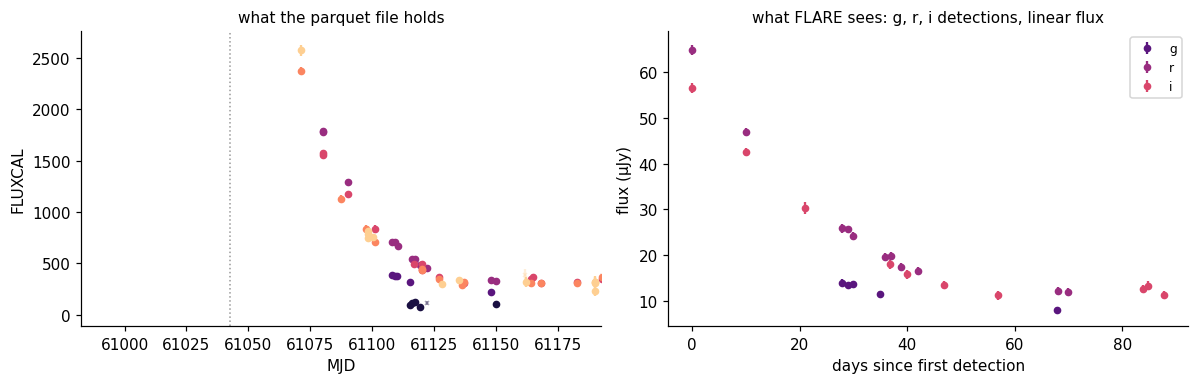

In [6]:
def plot_events(arr, ax, title=""):
    bands = D.reconstruct_bands(arr)
    for name, lc in bands.items():
        ax.errorbar(lc.t, lc.flux, lc.flux_err, fmt="o", ms=4, color=BAND_COLOR[name], label=name)
    ax.set_xlabel("days since first detection"); ax.set_ylabel("flux (µJy)"); ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
plot_raw(h, h, axes[0]); axes[0].set_title("what the parquet file holds", fontsize=10)
plot_events(arr, axes[1], "what FLARE sees: g, r, i detections, linear flux")
plt.tight_layout(); plt.show()

## 4. Cadence reality check: what survives?

FLARE's training pipeline applies a quality cut before extracting features (`flare.data.passes_quality`):
at least 8 usable observations, at least 2 in *g* and 2 in *r*, in at least two bands. On ZTF, which
revisits every field in *g* and *r* every two nights, nearly everything passes. Let us measure what
Rubin's cadence does to each class, on a few hundred objects per model.

In [7]:
def quality(arr, min_total=6, min_g=1, min_r=1, min_bands=2):
    # Our relaxed version of flare.data.passes_quality (which asks 8 / 2 / 2 / 2).
    if arr is None or len(arr) < min_total:
        return False
    counts = np.bincount(arr[:, D.COL["band_id"]].astype(int), minlength=3)
    return counts[0] >= min_g and counts[1] >= min_r and (counts > 0).sum() >= min_bands

probe_ids = headers.groupby("obj_type", group_keys=False).apply(lambda g: g.sample(300, random_state=SEED)).SNID
probe = read_phot(snids=probe_ids.tolist()).merge(headers[["SNID", "obj_type", "cls"]], on="SNID")
rows = []
for r in probe.itertuples():
    a = sassafras_to_events(r.mjd, r.band, r.fluxcal, r.fluxcalerr, r.photflag)
    rows.append({"cls": r.cls, "obj_type": r.obj_type, "n_events": 0 if a is None else len(a),
                 "flare default (8/2/2)": D.passes_quality(a) if a is not None else False,
                 "relaxed (6/1/1)": quality(a)})
survival = pd.DataFrame(rows)
tab = survival.groupby("obj_type")[["flare default (8/2/2)", "relaxed (6/1/1)"]].mean()
tab["median events"] = survival.groupby("obj_type").n_events.median()
tab.round(2).sort_values("relaxed (6/1/1)")

,flare default (8/2/2),relaxed (6/1/1),median events
obj_type,,,
KN_B19,0.01,0.02,0.0
KN_K17,0.01,0.03,2.0
SNIa-91bg,0.07,0.14,4.0
SNIax,0.16,0.32,6.0
SNIIb+HostXT_V19,0.20,0.33,7.0
CART,0.20,0.37,6.0
SNIcBL+HostXT_V19,0.25,0.37,7.0
SNIb+HostXT_V19,0.24,0.38,8.0
SNIc+HostXT_V19,0.21,0.38,8.0


**This table is the lesson.** With ZTF-style requirements, a kilonova essentially never qualifies:
the median SASSAFRAS kilonova has *one or two* 3σ detections in *g, r, i* before it is gone. We keep
the relaxed cut (6 events, at least one in *g* and one in *r*) so that every class is represented, and
we accept that the kilonovae that pass are the luckiest and nearest ones. Remember this selection when
you read the kilonova results later: a classifier can only learn the kilonovae Rubin can actually see.

## 5. Part 0: build the lesson sample

We now draw up to `N_PER_MODEL` qualifying objects per simulation model (so the eight classes are
reasonably balanced), convert each to a FLARE array, and cache the result. Reading the 831 MB file
once per model and converting about 100,000 light curves takes a few minutes; the cache is a few
megabytes and the rest of the lesson starts from it.

In [8]:
N_PER_MODEL = 600
EVENTS_FILE, META_FILE = PREP_DIR / "sassafras_events.npz", PREP_DIR / "sassafras_meta.csv"

if EVENTS_FILE.exists() and META_FILE.exists():
    with np.load(EVENTS_FILE) as z:
        events = {k: z[k] for k in z.files}
    meta = pd.read_csv(META_FILE, dtype={"SNID": str})
    print(f"loaded cache: {len(meta):,} objects")
else:
    assert PHOT.exists(), f"Part 0 needs {PHOT}. Download it from https://zenodo.org/records/20262635."
    events, meta_rows, t0 = {}, [], time.time()
    for obj_type in sorted(TEACHING_CLASS):
        tbl = read_phot(obj_type=obj_type)
        tbl = tbl.sample(frac=1.0, random_state=SEED)              # shuffle so we do not take the first file only
        n_ok = 0
        for r in tbl.itertuples():
            a = sassafras_to_events(r.mjd, r.band, r.fluxcal, r.fluxcalerr, r.photflag)
            if not quality(a):
                continue
            events[r.SNID] = a
            n_ok += 1
            if n_ok >= N_PER_MODEL:
                break
        print(f"  {obj_type:20s} {n_ok:4d} kept of {len(tbl):6d} available   ({time.time()-t0:4.0f} s)")
    meta = headers[headers.SNID.isin(events)].reset_index(drop=True)
    meta["n_events"] = meta.SNID.map(lambda s: len(events[s]))
    np.savez_compressed(EVENTS_FILE, **events)
    meta.to_csv(META_FILE, index=False)
    print(f"cached {len(meta):,} objects -> {PREP_DIR}")

meta["y"] = meta.cls.map(CLASS_ID)
print(meta.cls.value_counts().reindex(CLASSES).to_frame("objects").T)

loaded cache: 8,400 objects
cls      SN Ia  SN Ibc  SN II  SLSN  TDE    KN  CART  ILOT
objects   1800    1800   1200   600  600  1200   600   600


## 6. From curves to numbers: the 160 FLARE features

A decision tree cannot look at a plot. FLARE summarises each band with statistics from the
`light-curve` package (amplitude, skewness, Stetson K, linear trend, and twenty more), a **Bazin fit**
(an exponential rise and decay that gives a rise time, a fall time, an amplitude and a goodness of fit),
cadence counts, and cross-band quantities: the *g − r* and *r − i* colours and how they drift with time.
`extract_from_array` returns a flat dictionary of 160 numbers; a missing band or a failed fit gives
`NaN`, which LightGBM treats as its own category rather than a problem.

In [9]:
@contextlib.contextmanager
def quiet_c_stderr():
    # The Bazin fitter logs failed fits to the C-level stderr; silence it while we loop.
    saved, devnull = os.dup(2), os.open(os.devnull, os.O_WRONLY)
    try:
        os.dup2(devnull, 2); yield
    finally:
        os.dup2(saved, 2); os.close(devnull); os.close(saved)

FEAT_FILE = PREP_DIR / "sassafras_features.parquet"
if FEAT_FILE.exists():
    feats = pd.read_parquet(FEAT_FILE)
    print("loaded cached features", feats.shape)
else:
    t0, rows = time.time(), []
    with quiet_c_stderr():
        for snid in meta.SNID:
            f = extract_from_array(events[snid]); f["SNID"] = snid; rows.append(f)
    feats = pd.DataFrame(rows).set_index("SNID")
    feats = feats[sorted(feats.columns)]
    feats.to_parquet(FEAT_FILE)
    print(f"extracted {feats.shape[1]} features for {len(feats):,} objects in {time.time()-t0:.0f} s")

FEATURES = list(feats.columns)
X_all = feats.loc[meta.SNID].reset_index(drop=True)
y_all = meta.y.values
print("fraction of NaN cells:", round(float(X_all.isna().mean().mean()), 3))
print([c for c in FEATURES if c.startswith("r_")][:12], "...")

loaded cached features (8400, 160)
fraction of NaN cells: 0.354
['r_amplitude', 'r_anderson_darling_normal', 'r_bazin_amplitude', 'r_bazin_baseline', 'r_bazin_fall_over_rise', 'r_bazin_fall_time', 'r_bazin_reduced_chi2', 'r_bazin_reference_time', 'r_bazin_rise_time', 'r_beyond_1_std', 'r_beyond_2_std', 'r_chi2'] ...


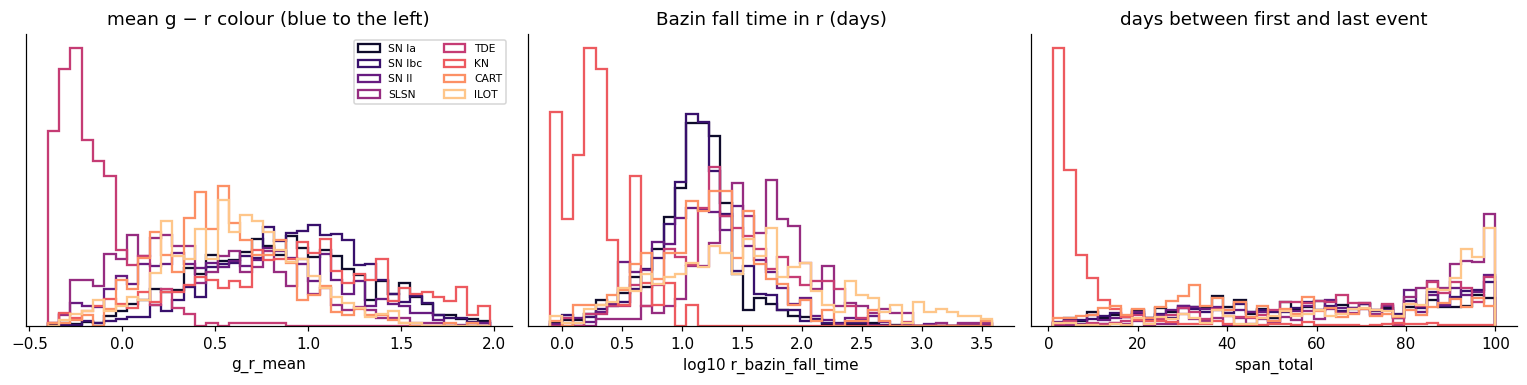

In [10]:
def feature_by_class(ax, col, log=False, bins=40):
    v = X_all[col]
    if log: v = np.log10(v.clip(1e-3))
    lo, hi = np.nanpercentile(v, [1, 99])
    for c in CLASSES:
        ax.hist(v[y_all == CLASS_ID[c]].dropna(), bins=np.linspace(lo, hi, bins), histtype="step",
                lw=1.5, density=True, color=CLASS_COLOR[c], label=c)
    ax.set_xlabel(("log10 " if log else "") + col); ax.set_yticks([])

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
feature_by_class(axes[0], "g_r_mean");        axes[0].set_title("mean g − r colour (blue to the left)")
feature_by_class(axes[1], "r_bazin_fall_time", log=True); axes[1].set_title("Bazin fall time in r (days)")
feature_by_class(axes[2], "span_total");      axes[2].set_title("days between first and last event")
axes[0].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

Three numbers already tell a physical story: TDEs and SLSNe sit at the blue end and have the longest
fall times, kilonovae are gone within days, SNe Ia redden as they age. The classifier's job is to use
all 160 at once.

## 6b. The old model on the new sky

FLARE ships two pretrained ZTF models: `broad5` (SN I, SN II, CV, AGN, TDE) and `bts6` (SN Ia, SN CC,
SLSN, AGN, TDE, CV). They were trained on real ZTF light curves of the Bright Transient Survey, which is
a magnitude-limited survey of *nearby* objects observed every two nights. What happens when we show them
Rubin simulations that are fainter, sparser, and redshifted? The features are the same 160 numbers, so
nothing stops us from asking. The external context columns (host galaxy, Gaia, WISE) are left `NaN`,
which the models accept by design.

In [11]:
ztf5 = flare.load_classifier("broad5")
ztf6 = flare.load_classifier("bts6")
P5 = ztf5.predict_proba(X_all[ztf5.feature_names] if set(ztf5.feature_names) <= set(FEATURES) else X_all)
P6 = ztf6.predict_proba(X_all.reindex(columns=ztf6.feature_names))     # context columns -> NaN
from flare.hierarchical import SIX
pred5 = np.array(ztf5.classes)[P5.argmax(1)] if hasattr(ztf5, "classes") else np.array(["SNI","SNII","CV","AGN","TDE"])[P5.argmax(1)]
pred6 = np.array(SIX)[P6.argmax(1)]

def rowtab(pred, name):
    t = pd.crosstab(meta.cls, pred, normalize="index").reindex(CLASSES)
    t.columns.name = name; return t.round(2)
display(rowtab(pred5, "broad5 (ZTF) says ->"))
display(rowtab(pred6, "bts6 (ZTF) says ->"))

broad5 (ZTF) says ->,AGN,CV,SNI,SNII,TDE
cls,,,,,
SN Ia,0.59,0.00,0.35,0.06,0.00
SN Ibc,0.63,0.01,0.28,0.09,0.00
SN II,0.70,0.01,0.20,0.08,0.00
SLSN,0.49,0.03,0.11,0.35,0.02
TDE,0.88,0.02,0.07,0.00,0.03
KN,0.70,0.27,0.02,0.00,0.00
CART,0.80,0.00,0.14,0.05,0.00
ILOT,1.00,0.00,0.00,0.00,0.00


bts6 (ZTF) says ->,AGN,CV,SLSN,SN_CC,SN_Ia,TDE
cls,,,,,,
SN Ia,0.00,0.03,0.00,0.39,0.57,0.0
SN Ibc,0.00,0.03,0.00,0.52,0.46,0.0
SN II,0.02,0.04,0.00,0.49,0.44,0.0
SLSN,0.01,0.01,0.07,0.71,0.20,0.0
TDE,0.08,0.05,0.05,0.35,0.47,0.0
KN,0.00,0.41,0.00,0.09,0.49,0.0
CART,0.00,0.08,0.00,0.34,0.57,0.0
ILOT,0.08,0.02,0.01,0.82,0.07,0.0


**What to notice.** The ZTF models were never shown a kilonova, a calcium-rich transient, or an ILOT, so
they cannot name them; the fair question is where they *put* things.

- `broad5` files most of the Rubin sample under **AGN**. In the ZTF world, "AGN" is the class of slow,
  low-amplitude, irregular variability over years, and that is exactly what a sparsely sampled explosion
  looks like when you only have a dozen points: no clean rise, no clean decline.
- `bts6` has a richer notion of a supernova, and it does recognise more than half of the SNe Ia as
  **SN Ia** and sorts most explosions into the supernova classes. But not one Rubin TDE is called a TDE
  (on ZTF the TDE signature is a long, blue, well-sampled plateau), and 41% of the kilonovae become
  **CV**, the ZTF class of short outbursts. The model is matching *shapes it knows*, not physics it does not.

That is **domain shift**: a model is only as good as the sky it was trained on, and a change of
cadence, depth and redshift range is a change of sky. So let us train on the right one.

## 7. A Rubin classifier

We split the objects into train, validation and test sets, **stratified by class**, so that the
proportions are the same in each. The validation set decides when to stop adding trees (early stopping)
and which class weighting to use; the test set is opened once, at the end.

In [12]:
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import balanced_accuracy_score, f1_score, confusion_matrix

idx = np.arange(len(meta))
idx_trainval, idx_test = train_test_split(idx, test_size=0.2, stratify=y_all, random_state=SEED)
idx_train, idx_val = train_test_split(idx_trainval, test_size=0.25, stratify=y_all[idx_trainval], random_state=SEED)
X_train, y_train = X_all.iloc[idx_train], y_all[idx_train]
X_val, y_val = X_all.iloc[idx_val], y_all[idx_val]
X_test, y_test = X_all.iloc[idx_test], y_all[idx_test]
print(f"train {len(idx_train)}, validation {len(idx_val)}, test {len(idx_test)}")

PARAMS = {"objective": "multiclass", "num_class": len(CLASSES), "metric": "multi_logloss",
          "learning_rate": 0.05, "num_leaves": 31, "min_data_in_leaf": 20, "feature_fraction": 0.8,
          "bagging_fraction": 0.8, "bagging_freq": 1, "verbosity": -1, "seed": SEED, "num_threads": 8}

def train_lgbm(X, y, Xv, yv, beta=0.5, n_classes=len(CLASSES)):
    # beta = 0: no reweighting; beta = 1: every class counts the same in the loss.
    counts = np.bincount(y, minlength=n_classes).astype(float)
    w = ((len(y) / (n_classes * counts)) ** beta)[y]
    dtrain = lgb.Dataset(X, label=y, weight=w)
    dval = lgb.Dataset(Xv, label=yv, reference=dtrain)
    evals = {}
    model = lgb.train(PARAMS | {"num_class": n_classes}, dtrain, num_boost_round=3000,
                      valid_sets=[dtrain, dval], valid_names=["train", "val"],
                      callbacks=[lgb.early_stopping(100, verbose=False), lgb.record_evaluation(evals)])
    return model, evals

print("beta   val accuracy   val balanced accuracy")
candidates = {}
for beta in [0.0, 0.5, 1.0]:
    m, ev = train_lgbm(X_train, y_train, X_val, y_val, beta=beta)
    p = m.predict(X_val, num_iteration=m.best_iteration).argmax(1)
    candidates[beta] = (m, ev)
    print(f"{beta:.1f}      {np.mean(p == y_val):.3f}            {balanced_accuracy_score(y_val, p):.3f}      ({m.best_iteration} trees)")
BETA = max(candidates, key=lambda b: balanced_accuracy_score(
    y_val, candidates[b][0].predict(X_val, num_iteration=candidates[b][0].best_iteration).argmax(1)))
model, evals = candidates[BETA]
print(f"chosen on validation: beta = {BETA}")

train 5040, validation 1680, test 1680
beta   val accuracy   val balanced accuracy


0.0      0.627            0.643      (87 trees)


0.5      0.640            0.665      (97 trees)


1.0      0.637            0.669      (107 trees)


chosen on validation: beta = 1.0


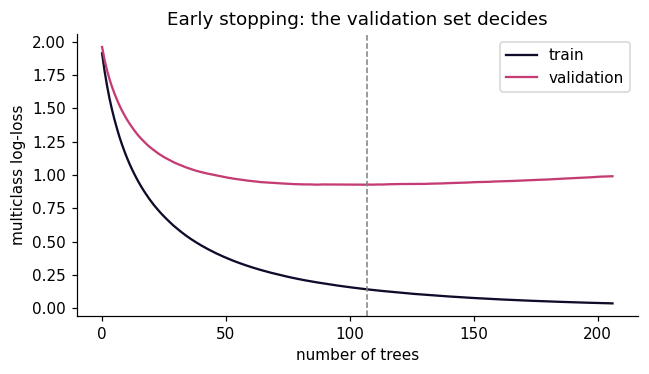

In [13]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(evals["train"]["multi_logloss"], color=CLASS_COLOR["SN Ia"], label="train")
ax.plot(evals["val"]["multi_logloss"], color=CLASS_COLOR["TDE"], label="validation")
ax.axvline(model.best_iteration, ls="--", color="0.5", lw=1)
ax.set_xlabel("number of trees"); ax.set_ylabel("multiclass log-loss"); ax.set_title("Early stopping: the validation set decides")
ax.legend(); plt.tight_layout(); plt.show()

TEST accuracy           0.623
TEST balanced accuracy  0.651
TEST macro F1           0.647


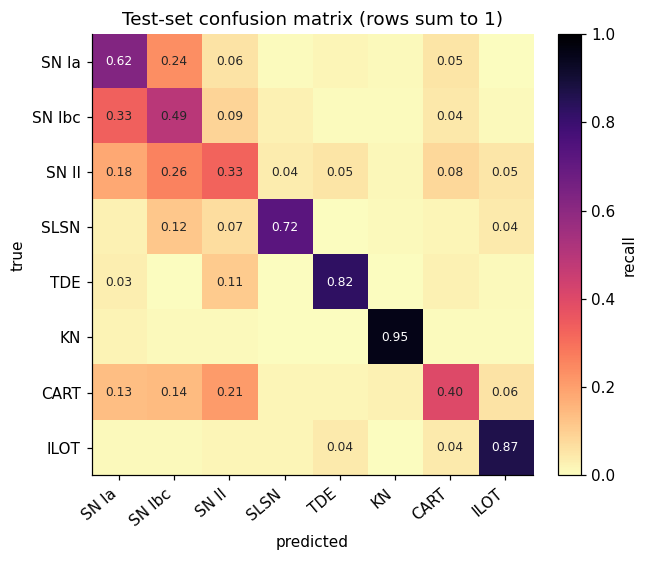

In [14]:
P_test = model.predict(X_test, num_iteration=model.best_iteration)
pred_test = P_test.argmax(1)
print(f"TEST accuracy           {np.mean(pred_test == y_test):.3f}")
print(f"TEST balanced accuracy  {balanced_accuracy_score(y_test, pred_test):.3f}")
print(f"TEST macro F1           {f1_score(y_test, pred_test, average='macro'):.3f}")

cm = confusion_matrix(y_test, pred_test, labels=range(len(CLASSES)))
cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(6, 5.2))
im = ax.imshow(cmn, cmap="magma_r", vmin=0, vmax=1)
ax.set_xticks(range(len(CLASSES))); ax.set_yticks(range(len(CLASSES)))
ax.set_xticklabels(CLASSES, rotation=40, ha="right"); ax.set_yticklabels(CLASSES)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        if cmn[i, j] >= 0.03:
            ax.text(j, i, f"{cmn[i,j]:.2f}", ha="center", va="center", fontsize=8, color="white" if cmn[i, j] > 0.5 else "0.15")
ax.set_title("Test-set confusion matrix (rows sum to 1)")
fig.colorbar(im, fraction=0.046, label="recall"); plt.tight_layout(); plt.show()

**Reading the matrix.** The diagonal is strong where the physics is distinctive: kilonovae (gone in a
week), ILOTs, TDEs (blue for months) and SLSNe (slow). The upper-left block is honest too: SN Ia, SN Ibc
and SN II share time scales, and with a dozen *g, r, i* points at redshift 0.3 their colours overlap, so
the model mixes them, exactly as photometric classifiers do on real ZTF data. CART is the hardest class:
faint, fast, and sitting between the supernovae and the ILOTs.

One caution before you celebrate the kilonova row. Our kilonovae are the few percent that produced six
detections within days, so "short span, few points, red" identifies them almost perfectly *in this
sample*. Is the model learning kilonova physics, or learning what Rubin's cadence does to a fast
transient? Exercise 2 is about this question.

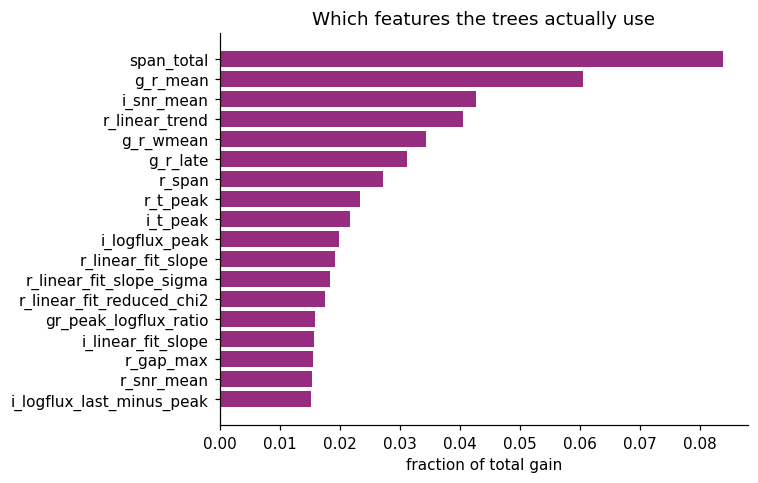

In [15]:
imp = pd.Series(model.feature_importance("gain"), index=model.feature_name()).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 4.5))
top = imp.head(18)[::-1]
ax.barh(top.index, top.values / imp.sum(), color=CLASS_COLOR["SLSN"])
ax.set_xlabel("fraction of total gain"); ax.set_title("Which features the trees actually use")
plt.tight_layout(); plt.show()

Colour statistics, Bazin time scales and the span of the detections dominate: the model found the same
physics we read off the histograms in Part 6, now weighted and combined.

## 8. Honest uncertainty: prediction sets

A probability of 0.55 for "SN Ibc" sounds precise, but is it *right*? **Conformal prediction** gives a
guarantee you can check: for each class, pick the threshold $\hat q_c$ on the validation set such that the
true class scores above $1-\hat q_c$ for 90% of its objects. At test time, the prediction set is every
class whose probability clears its own threshold. Sometimes the set has one member (the model is sure),
sometimes two or three (the honest answer is "one of these"), and for exactly 10% of each class, the
true label is missing, by construction. This is FLARE's Mondrian (class-conditional) calibration,
written out for eight classes.

In [16]:
def conformal_calibrate(P_cal, y_cal, alpha=0.10):
    qhat = np.ones(P_cal.shape[1])
    for c in range(P_cal.shape[1]):
        s = 1.0 - P_cal[y_cal == c, c]                   # non-conformity: how far the true class fell below 1
        n = len(s)
        if n:
            k = int(np.ceil((n + 1) * (1 - alpha)))
            qhat[c] = 1.0 if k > n else np.sort(s)[k - 1]
    return qhat

def prediction_sets(P, qhat):
    return P >= (1.0 - qhat)[None, :]

P_val = model.predict(X_val, num_iteration=model.best_iteration)
qhat = conformal_calibrate(P_val, y_val, alpha=0.10)
sets = prediction_sets(P_test, qhat)

rep = pd.DataFrame({
    "n": [int((y_test == c).sum()) for c in range(len(CLASSES))],
    "coverage": [sets[y_test == c, c].mean() for c in range(len(CLASSES))],
    "mean set size": [sets[y_test == c].sum(1).mean() for c in range(len(CLASSES))],
    "singletons": [(sets[y_test == c].sum(1) == 1).mean() for c in range(len(CLASSES))],
}, index=CLASSES)
print("target coverage: 0.90   marginal:", round(float(sets[np.arange(len(y_test)), y_test].mean()), 3))
rep.round(3)

target coverage: 0.90   marginal: 0.917


,n,coverage,mean set size,singletons
SN Ia,360,0.919,2.947,0.075
SN Ibc,360,0.922,2.989,0.050
SN II,240,0.908,3.104,0.050
SLSN,120,0.917,1.983,0.567
TDE,120,0.942,1.792,0.592
KN,240,0.888,1.121,0.912
CART,120,0.917,3.033,0.075
ILOT,120,0.942,1.858,0.500


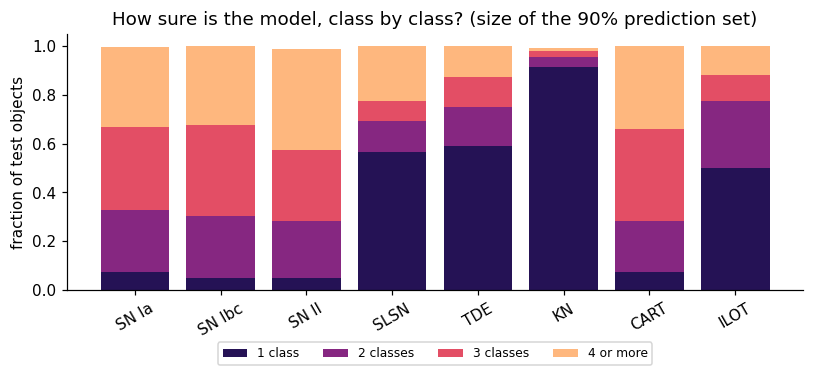

,objects
SN Ia + SN Ibc + SN II,177
SN Ia + SN Ibc,120
SN Ibc + SN II + CART,57
SN Ia + SN II + CART,53
SN II + CART,52
SN Ia + SN II,34
SN Ibc + SN II,31
SN II + TDE + CART,29


In [17]:
sizes = sets.sum(1)
size_bins = {"1 class": sizes == 1, "2 classes": sizes == 2, "3 classes": sizes == 3, "4 or more": sizes >= 4}
frac = pd.DataFrame({k: [v[y_test == CLASS_ID[c]].mean() for c in CLASSES] for k, v in size_bins.items()}, index=CLASSES)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
bottom = np.zeros(len(CLASSES))
for (k, col), shade in zip(frac.items(), plt.cm.magma(np.linspace(0.15, 0.85, 4))):
    ax.bar(CLASSES, col.values, bottom=bottom, color=shade, label=k); bottom += col.values
ax.set_ylabel("fraction of test objects"); ax.set_title("How sure is the model, class by class? (size of the 90% prediction set)")
ax.legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18)); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

# the most frequent sets: which classes travel together?
pairs = pd.Series([" + ".join(np.array(CLASSES)[s]) for s in sets if 1 < s.sum() <= 3]).value_counts().head(8)
pairs.to_frame("objects")

The co-occurring sets are the classifier admitting what the confusion matrix showed: the three supernova
families travel together, and CART attaches itself to SN II. Kilonovae, TDEs and SLSNe mostly get a set of
one. For a telescope scheduler, a three-class set is not a failure; it is a precise request: *this object
needs a spectrum to be resolved*, and the set says which spectral features to look for.

## 9. Can the classifier be surprised?

The most valuable Rubin discoveries will be objects nobody put in the training set. FLARE's anomaly
layer scores an object by the **energy** of the classifier's raw outputs: for a LightGBM multiclass
model the raw scores $z_c$ play the role of logits, and $E = -\log \sum_c e^{z_c}$ is low when some
class claims the object confidently and high when none does. A second, model-free idea is **distance**:
standardise the features and measure how far an object sits from its nearest training neighbours.

We test both the honest way. For each class in turn we pretend it was never catalogued: train a
seven-class model on the other classes, score the held-out class and the known test objects, and
measure how well the score separates them (the area under the ROC curve: 0.5 is a coin flip, 1.0 is
perfect).

In [18]:
from scipy.special import logsumexp
from sklearn.metrics import roc_auc_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

def energy(m, X):
    z = m.predict(X, num_iteration=m.best_iteration, raw_score=True)
    return -logsumexp(z, axis=1)

results, scores = [], {}
for holdout in CLASSES:
    k = CLASS_ID[holdout]
    known = [c for c in range(len(CLASSES)) if c != k]
    remap = {c: i for i, c in enumerate(known)}
    def without(idx):
        m = y_all[idx] != k
        return X_all.iloc[idx[m]], np.array([remap[c] for c in y_all[idx[m]]])
    Xk_train, yk_train = without(idx_train); Xk_val, yk_val = without(idx_val); Xk_test, _ = without(idx_test)
    X_out = X_all[y_all == k]
    model7, _ = train_lgbm(Xk_train, yk_train, Xk_val, yk_val, beta=BETA, n_classes=len(known))
    labels = np.r_[np.zeros(len(Xk_test)), np.ones(len(X_out))]
    e = np.r_[energy(model7, Xk_test), energy(model7, X_out)]
    # distance in standardised feature space (NaN -> training median), mean distance to 10 neighbours
    med = Xk_train.median()
    scaler = StandardScaler().fit(Xk_train.fillna(med))
    nn = NearestNeighbors(n_neighbors=10).fit(scaler.transform(Xk_train.fillna(med)))
    dist = lambda X: nn.kneighbors(scaler.transform(X.fillna(med)))[0].mean(1)
    d = np.r_[dist(Xk_test), dist(X_out)]
    scores[holdout] = (labels, e, d)
    results.append({"held out": holdout, "energy AUROC": roc_auc_score(labels, e), "distance AUROC": roc_auc_score(labels, d)})
results = pd.DataFrame(results).set_index("held out")
results.round(2)

,energy AUROC,distance AUROC
held out,,
SN Ia,0.63,0.46
SN Ibc,0.65,0.49
SN II,0.70,0.50
SLSN,0.59,0.82
TDE,0.54,0.65
KN,0.38,0.50
CART,0.75,0.42
ILOT,0.65,0.71


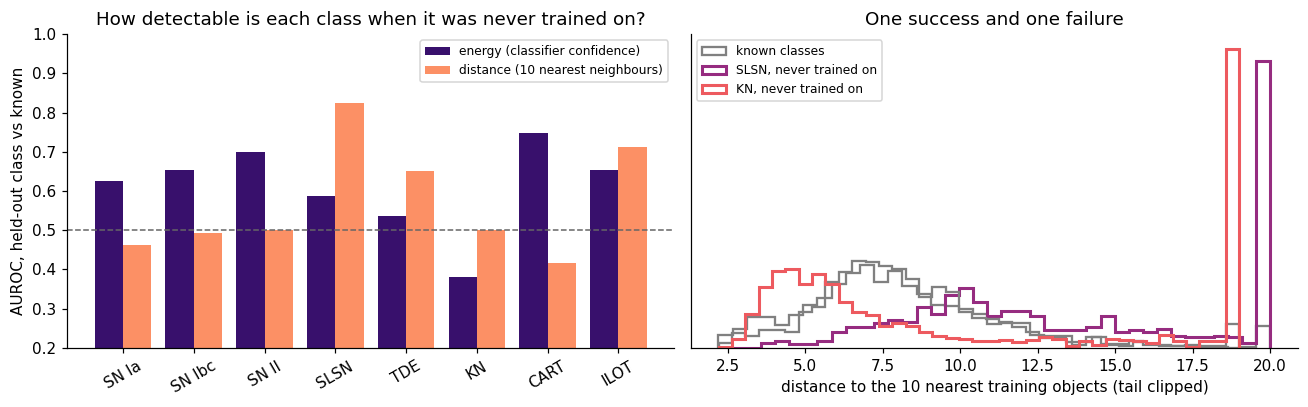

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
xs = np.arange(len(CLASSES))
axes[0].bar(xs - 0.2, results["energy AUROC"], 0.4, color=CLASS_COLOR["SN Ibc"], label="energy (classifier confidence)")
axes[0].bar(xs + 0.2, results["distance AUROC"], 0.4, color=CLASS_COLOR["CART"], label="distance (10 nearest neighbours)")
axes[0].axhline(0.5, color="0.4", ls="--", lw=1); axes[0].set_xticks(xs); axes[0].set_xticklabels(CLASSES, rotation=30)
axes[0].set_ylabel("AUROC, held-out class vs known"); axes[0].set_ylim(0.2, 1); axes[0].legend(fontsize=8)
axes[0].set_title("How detectable is each class when it was never trained on?")
for name, col in [("SLSN", CLASS_COLOR["SLSN"]), ("KN", CLASS_COLOR["KN"])]:
    labels, e, d = scores[name]
    bins = np.linspace(d.min(), np.percentile(d[labels == 0], 98), 40)      # clip the long tail for legibility
    d = np.clip(d, None, bins[-1])
    axes[1].hist(d[labels == 0], bins, density=True, histtype="step", lw=1.5, color="0.5", label="known classes" if name == "SLSN" else None)
    axes[1].hist(d[labels == 1], bins, density=True, histtype="step", lw=2, color=col, label=f"{name}, never trained on")
axes[1].set_xlabel("distance to the 10 nearest training objects (tail clipped)"); axes[1].set_yticks([]); axes[1].legend(fontsize=8)
axes[1].set_title("One success and one failure")
plt.tight_layout(); plt.show()

**Two regimes, and a lesson that no slide can teach as well as this plot.**

- **Superluminous supernovae** are found by distance: months long, blue, luminous, they sit far from every
  other training object in feature space. TDEs and ILOTs are partly found. This is how FLARE's anomaly
  layer on ZTF catches rare transients among well-measured curves.
- **Supernova subtypes** held out one at a time are never found. A missing SN Ibc lands inside the SN Ia
  and SN II cloud; nothing about it is strange. Anomaly detection finds the *different*, not the *absent*.
- **Kilonovae** are the failure that matters for Rubin. The confidence-based score does worse than a coin
  flip: a kilonova with six points and most features `NaN` falls into the few leaves the trees reserve
  for sparse, faint objects, and the model is *confident* there. The distance score cannot see it either,
  because six points leave little to measure. You cannot be surprised by something you barely saw.

The kilonova problem on Rubin is therefore a **cadence** problem before it is a feature problem: the
discovery has to happen in real time, from the first one or two detections and their colour, and with
help from outside the survey (a gravitational-wave alert, a host galaxy at the right distance). That is
the direction of exercise 2 and 4.

## 10. What you built, and exercises

You went from a Zenodo record to a working Rubin transient classifier with calibrated uncertainty and a
novelty detector, using the same data format and the same feature extractor that FLARE runs on ZTF
alerts. Everything you changed lived in one function, `sassafras_to_events`.

**Exercises**

1. **Bring back u, z, y.** FLARE's feature extractor is built around *g, r, i*. Write a converter that
   maps Rubin *r, i, z* to the three FLARE slots instead, retrain, and compare the balanced accuracy.
   Which classes gain? (Think about which part of the spectrum a redshift-0.8 SLSN puts into each filter.)
2. **Physics or survey?** Remove every cadence feature (`n_obs_total`, `span_total`, the per-band
   `*_n_obs`, `*_span`, `*_max_gap`) from `X_all` and retrain. How much of the kilonova recall survives?
   Then rerun Part 0 with `horizon_days=10` and a looser quality cut to classify objects ten days after
   their first detection: which classes can be named early, and which need the full curve?
3. **Context helps.** The headers contain the host galaxy's *g, r, i* magnitudes and the separation
   between transient and host (`HOSTGAL_MAG_*`, `HOSTGAL_SNSEP`). Add them as extra columns to `X_all`
   and retrain. Which confusion shrinks? Why does the host matter for TDEs in particular?
4. **A kilonova detector that uses the right information.** For every object keep only the first three
   detections and build three numbers: the first colour, the rise or fall rate between the first two
   epochs in the same band, and the host separation from the headers. Train a kilonova-versus-rest model
   on these and compare its recall at a 5% false-alarm rate with Part 9.
7. **Redshift dependence.** Bin the test set by `REDSHIFT_FINAL` and plot the balanced accuracy per
   bin. At what redshift does photometric classification stop working for each class?
5. **Honest sets in practice.** Change `alpha` to 0.05 and 0.20. How does the mean set size respond?
   If a spectrograph can follow up 20 objects a night, which value would you choose?
6. **The hard pairs.** Train a binary CART-versus-ILOT model with only ten features of your choice and
   see how close you get to the full model. Which features did you need?